# Quantum Gate Synthesis and Fidelity

### 1. What is a quantum gate?

A quantum gate is a controlled operation that transforms the state of a quantum system. In a physical quantum processor they are implemented by controlling the system's Hamiltonian over a finite duration. Our objective is therefore to find control signals whose resulting quantum evolution approximates a desired unitary operation.

**Pauli gates: $X$, $Y$, and $Z$**

$$
X=\begin{pmatrix}0&1\\1&0\end{pmatrix},
\quad
Y=\begin{pmatrix}0&-i\\i&0\end{pmatrix},
\quad
Z=\begin{pmatrix}1&0\\0&-1\end{pmatrix}.
$$

These gates correspond, up to global phase, to rotations by $\pi$ around the $x$, $y$, and $z$ axes of the Bloch sphere.

- **$X$:** exchanges $|0\rangle$ and $|1\rangle$, acting as a quantum bit flip.
- **$Y$:** performs a bit flip with phase factors.
- **$Z$:** changes the relative phase between $|0\rangle$ and $|1\rangle$, without changing their computational-basis populations.

**Hadamard gate: $H$**

$$
H=\frac{1}{\sqrt2}
\begin{pmatrix}1&1\\1&-1\end{pmatrix}
$$

The Hadamard gate maps computational basis states into equal superpositions:

$$
H|0\rangle=\frac{|0\rangle+|1\rangle}{\sqrt2},
\qquad
H|1\rangle=\frac{|0\rangle-|1\rangle}{\sqrt2}
$$

It prepares superpositions and enables interference between computational paths. For example, applying Hadamard gates to several qubits can prepare a uniform superposition over computational basis states. This is often described as quantum parallelism.

Other gates correspond to the rotation of a qubit by an angle $t$ around a Pauli  defined by:
$$
R_u(t) = e^{-i \frac{t}{2} \sigma_u} = \cos\left(\frac{t}{2}\right)I - i\sin\left(\frac{t}{2}\right)\sigma_u
$$
for $u \in \{x, y, z\}$.

For example phase gates $S = R_z(\pi/2)$, $T = R_z(\pi/2)$ and square root gates $\sqrt{X} = R_x(\pi/2)$, $\sqrt{Y} = R_y(\pi/2)$.

If the system evolves for a duration $T$, the resulting propagator $U(T)$ is the operation implemented by the system. Gate synthesis consists of choosing the available controls so that this propagator matches the desired target gate as closely as possible.

In [1]:

import numpy as np
import matplotlib.pyplot as plt

import sys
from pathlib import Path
root_path = Path.cwd().parent
sys.path.append(str(root_path / "src"))
from gates import *
from evolution import *
from fidelity import average_gate_fidelity
from optimization import monte_carlo_pulse_search

In [2]:
omega = 1
delta = 0.5

H_sys = hamiltonian(omega, 0.0, delta)
assert np.allclose(H_sys, H_sys.conj().T)
U_sys = propagator(H_sys, 1.0)
print("U(t):\n", U_sys)
print("Unitary:", np.allclose(
    U_sys.conj().T @ U_sys, np.eye(U_sys.shape[0])
))

U(t):
 [[ 8.47776861e-01-0.47436222j  6.93889390e-18-0.23718111j]
 [-2.75236841e-18-0.23718111j  8.47776861e-01+0.47436222j]]
Unitary: True


In [3]:
times = np.linspace(0, 2 * np.pi / np.sqrt(omega**2 + 4 * delta**2), 500)

fidelities_X = []

for t in times:
    U = propagator(H_sys, t)
    fidelities_X.append(average_gate_fidelity(X, U))

fidelities_X = np.array(fidelities_X)

best_idx = np.argmax(fidelities_X)

print(f"Best X-gate fidelity: {fidelities_X[best_idx]:.6f}")
print(f"Best evolution time: {times[best_idx]:.6f}")


Best X-gate fidelity: 0.466666
Best evolution time: 2.813529


### 2. Gate fidelity

In practice, the operation generated by the system does not necessarily match the target gate exactly.

To quantify this difference, we use the **average gate fidelity**:

$$
F_{\mathrm{avg}}(U_{\mathrm{target}},U(t))
=
\frac{
\left|\operatorname{Tr}(U_{\mathrm{target}}^\dagger U(t))\right|^2+d
}{
d(d+1)
}
$$

where $U_{\mathrm{target}}$ is the desired gate, $U(t) = e^{-iHt}$ is the actual propagator, and $d$ is the dimension of the Hilbert space.

For a single qubit, $d=2$. The fidelity satisfies

$$
\frac{1}{3}\leq F_{\mathrm{avg}}\leq 1
$$

for unitary single-qubit operations.

- $F_{\mathrm{avg}}=1$: the actual operation implements the target gate exactly, up to a physically irrelevant global phase.
- $F_{\mathrm{avg}}<1$: the actual operation differs from the target.
- A low fidelity indicates that the chosen Hamiltonian and control parameters do not generate an operation sufficiently close to the target.

**Assumptions:** This formula applies to unitary operations of the same dimension. It measures gate performance, not just the transfer of a particular initial state. Therefore, a high population transfer does not necessarily imply a high gate fidelity.


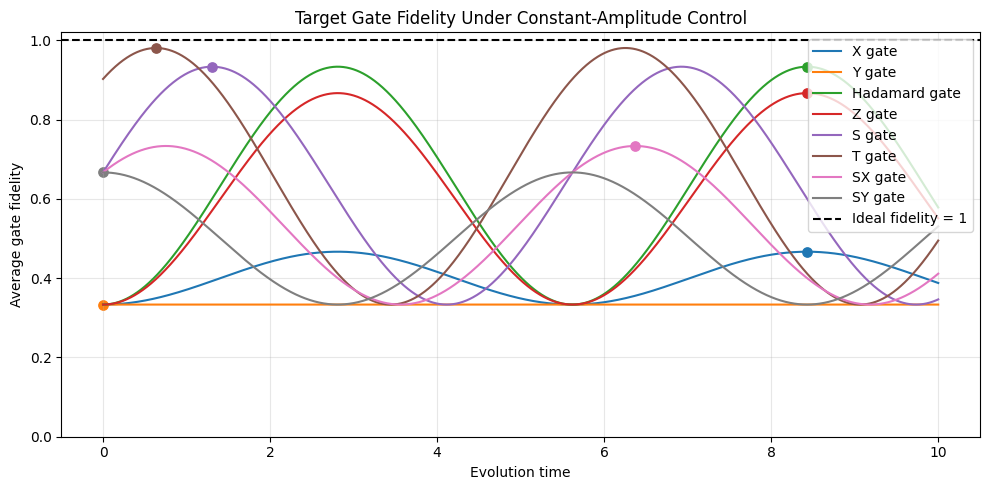

X          | Best fidelity: 0.466667 | Time: 8.4292
Y          | Best fidelity: 0.333333 | Time: 0.0000
Hadamard   | Best fidelity: 0.933333 | Time: 8.4292
Z          | Best fidelity: 0.866667 | Time: 8.4292
S          | Best fidelity: 0.933333 | Time: 1.3057
T          | Best fidelity: 0.980474 | Time: 0.6353
SX         | Best fidelity: 0.733333 | Time: 6.3732
SY         | Best fidelity: 0.666667 | Time: 0.0000


In [4]:

# Target gates
target_gates = {
    "X": X,
    "Y": Y,
    "Hadamard": H,
    "Z": Z,
    "S": S,
    "T": T,
    "SX": SX, 
    "SY": SY
}

times = np.linspace(0, 10, 2000)

plt.figure(figsize=(10, 5))

results = {}

for name, U_target in target_gates.items():
    fidelities = np.array([
        average_gate_fidelity(
            U_target,
            propagator(H_sys, t)
        )
        for t in times
    ])

    best_idx = np.argmax(fidelities)
    best_fidelity = fidelities[best_idx]
    best_time = times[best_idx]

    results[name] = {
        "best_fidelity": best_fidelity,
        "best_time": best_time,
    }

    plt.plot(times, fidelities, label=f"{name} gate")
    plt.scatter(best_time, best_fidelity, s=45)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    label="Ideal fidelity = 1"
)

plt.xlabel("Evolution time")
plt.ylabel("Average gate fidelity")
plt.title("Target Gate Fidelity Under Constant-Amplitude Control")
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

for name, result in results.items():
    print(
        f"{name:10s} | "
        f"Best fidelity: {result['best_fidelity']:.6f} | "
        f"Time: {result['best_time']:.4f}"
    )


### 3. Gate synthesis with a constant Hamiltonian

We first consider the controlled two-level system

$$
H=\frac{\omega}{2}\sigma_z+\delta\sigma_x,
$$

For fixed values of $\omega$ and $\delta$, the system evolves along a trajectory determined by a single, fixed rotation axis.

**Y gate:** The identity, $\sigma_x$, $\sigma_y$ and $\sigma_z$ matrices are orthogonal under the trace inner product: the trace of the product of two different Pauli matrices is zero. Since $U(t)$ contains no $\sigma_y$ component,
$$
\operatorname{Tr}(Y^\dagger U(t))=0.
$$

Therefore,
$$
\boxed{F_{\mathrm{avg}}(Y,U(t))=\frac13}
$$

for every time $t$, regardless of the values of $\omega$ and $\delta$, as long as the Hamiltonian retains this form.

The constant fidelity of the $Y$ gate does not mean that the system is static or that $Y$ gates are fundamentally impossible. It means that this particular family of propagators cannot synthesize $Y$ by varying time alone.

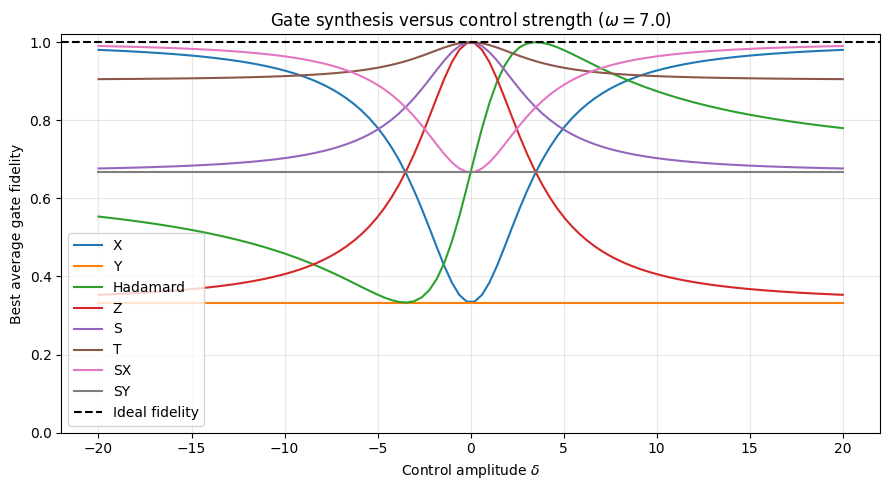

In [5]:

# Experiment 2: Best gate fidelity versus control amplitude

omega = 7.0
delta_values = np.linspace(-20.0, 20.0, 100)

best_fidelities = {name: [] for name in target_gates}

for delta_test in delta_values:
    H_test = (omega / 2) * sigma_z + delta_test * sigma_x

    # Sweep over one full period of the propagator
    lam = np.sqrt((omega / 2)**2 + delta_test**2)
    times_test = np.linspace(0, 2 * np.pi / lam, 800)

    for name, U_target in target_gates.items():
        values = [
            average_gate_fidelity(
                U_target,
                propagator(H_test, t)
            )
            for t in times_test
        ]

        best_fidelities[name].append(max(values))

plt.figure(figsize=(9, 5))

for name, values in best_fidelities.items():
    plt.plot(delta_values, values, label=name)

plt.axhline(1.0, color="black", linestyle="--",
            label="Ideal fidelity")

plt.xlabel(r"Control amplitude $\delta$")
plt.ylabel("Best average gate fidelity")
plt.title(r"Gate synthesis versus control strength ($\omega={}$)".format(omega))
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### 4. Fixed drift and increasing control amplitude

We next keep the drift frequency fixed while varying the control amplitude $\delta$:

$$
H_{\mathrm{sys}}(\delta)
=\frac{\omega}{2}\sigma_z+\delta\sigma_x.
$$

Increasing the control amplitude does not guarantee that every target gate becomes reachable. A stronger control along a single axis does not, by itself, provide arbitrary control over the rotation axis. For example, the fidelity with a $Y$ target remains $1/3$ for this constant $X$-control and $Z$-drift model.

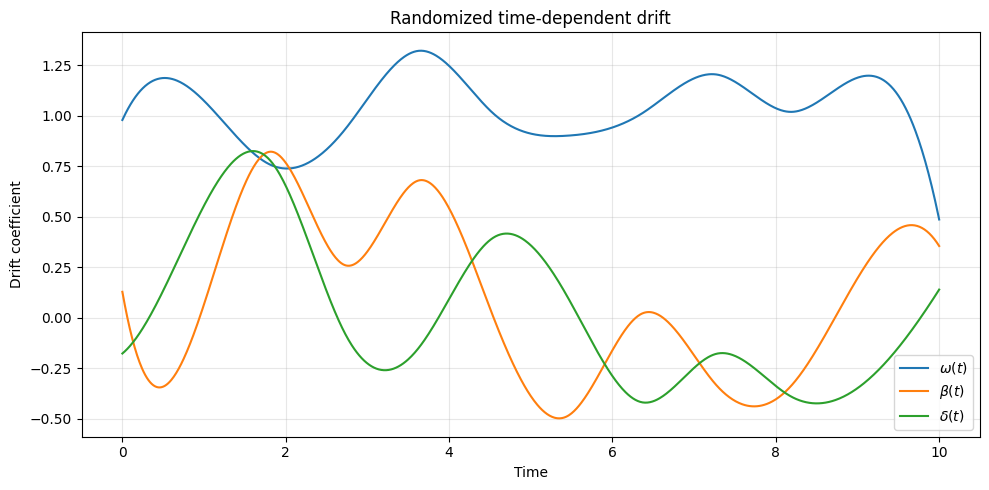

In [6]:
t_final = 10.0
n_steps = 1000
t_grid = np.linspace(0, t_final, n_steps + 1)

H_drift, drift_functions = generate_random_drift(t_grid, n_knots=12, amplitudes=(1.0, 0.3, 0.3))

omega_t, beta_t, delta_t = drift_functions

plt.figure(figsize=(10, 5))
plt.plot(t_grid, omega_t(t_grid), label=r"$\omega(t)$")
plt.plot(t_grid, beta_t(t_grid), label=r"$\beta(t)$")
plt.plot(t_grid, delta_t(t_grid), label=r"$\delta(t)$")

plt.xlabel("Time")
plt.ylabel("Drift coefficient")
plt.title("Randomized time-dependent drift")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 5. Randomized time-dependent drift

A constant drift is useful for establishing a baseline, but real quantum systems can experience time-dependent variations. To explore this, we introduce a synthetic drift Hamiltonian with time-varying coefficients:

$$
H_d(t)=\frac12\left[
\delta(t)\sigma_x+
\beta(t)\sigma_y+
\omega(t)\sigma_z
\right]
$$

In this experiment, they are generated from randomized values at a finite set of time knots and interpolated using cubic splines.

Maximum unitarity error: 7.086695280161792e-15


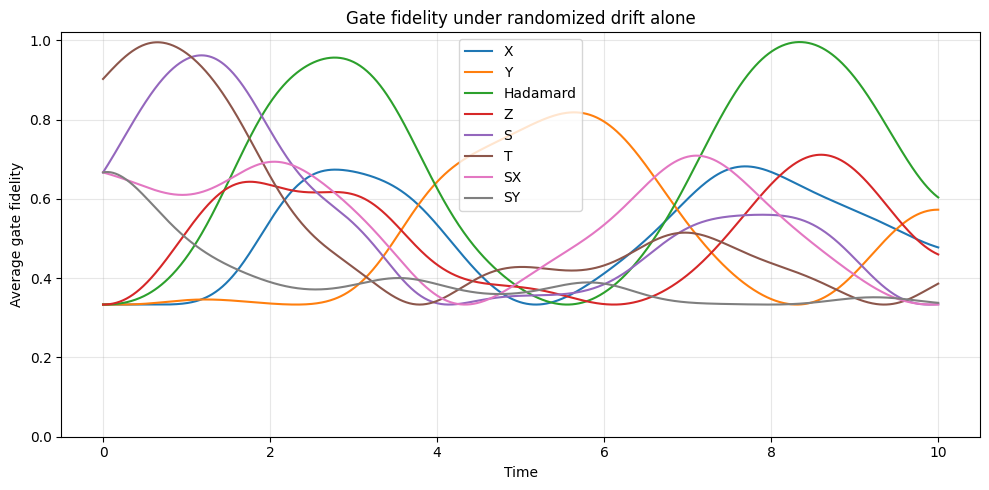

In [7]:
U_drift = propagate_time_dependent(H_drift, t_grid)

unitarity_errors = [
    np.linalg.norm(U.conj().T @ U - I)
    for U in U_drift
]

print("Maximum unitarity error:", max(unitarity_errors))


fidelities_drift = {name: [] for name in target_gates}

for U in U_drift:
    for name, U_target in target_gates.items():
        fidelities_drift[name].append(
            average_gate_fidelity(U_target, U)
        )

plt.figure(figsize=(10, 5))

for name, values in fidelities_drift.items():
    plt.plot(t_grid, values, label=name)

plt.xlabel("Time")
plt.ylabel("Average gate fidelity")
plt.title("Gate fidelity under randomized drift alone")
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

This establishes a baseline for the uncontrolled, time-dependent evolution. Fidelity may increase or decrease over time as the propagator moves closer to or farther from a target operation. Such changes do not necessarily represent decoherence: in this experiment, the Hamiltonian evolution remains unitary.

In [8]:
# Use the same drift realization and duration for all targets.
search_results = {}

for name, U_target in target_gates.items():
    best_pulse, best_fidelity, history = monte_carlo_pulse_search(H_drift=H_drift, U_target=U_target, t_grid=t_grid)

    search_results[name] = {
        "pulse": best_pulse,
        "fidelity": best_fidelity,
        "history": history
    }

    print(f"{name} gate")
    print("  Best fidelity:", best_fidelity)
    print("  Best pulse:", best_pulse)

Reached max samples (500).
X gate
  Best fidelity: 0.9676124189244537
  Best pulse: [-4.38164396  2.86528123  3.37185173  4.2609272  -3.18557135 -4.87085755]
Reached max samples (500).
Y gate
  Best fidelity: 0.9872901346583581
  Best pulse: [-1.94164273 -3.48921298 -4.95498958  1.95419988  2.94699299  0.62857605]
Hadamard gate
  Best fidelity: 0.9950850061077987
  Best pulse: [ 0.52896971 -3.88587143 -3.61897745 -3.23464305 -4.02396619  4.54822289]
Reached max samples (500).
Z gate
  Best fidelity: 0.9850958042093847
  Best pulse: [-2.04364224  2.85597058 -4.92380721  1.33898996  1.38251078 -1.4469513 ]
S gate
  Best fidelity: 0.9901733728805627
  Best pulse: [ 1.80282571 -0.12217334  1.0374023   3.16066812  2.0041589   4.64272412]
Reached max samples (500).
T gate
  Best fidelity: 0.9894342474754181
  Best pulse: [ 1.0308408   4.95531809  4.67175808 -2.66027523 -4.32160297 -3.59027614]
Reached max samples (500).
SX gate
  Best fidelity: 0.9884514635062979
  Best pulse: [ 4.7216319  -

### 6. Monte Carlo search for control pulses

The Monte Carlo sampler generates random candidate pulse amplitudes within a prescribed interval. Each candidate is simulated, its fidelity is evaluated, and the best candidate found so far is retained.

The search does not guarantee a globally optimal pulse. It provides a simple baseline against which more systematic methods, such as GRAPE, can be compared.

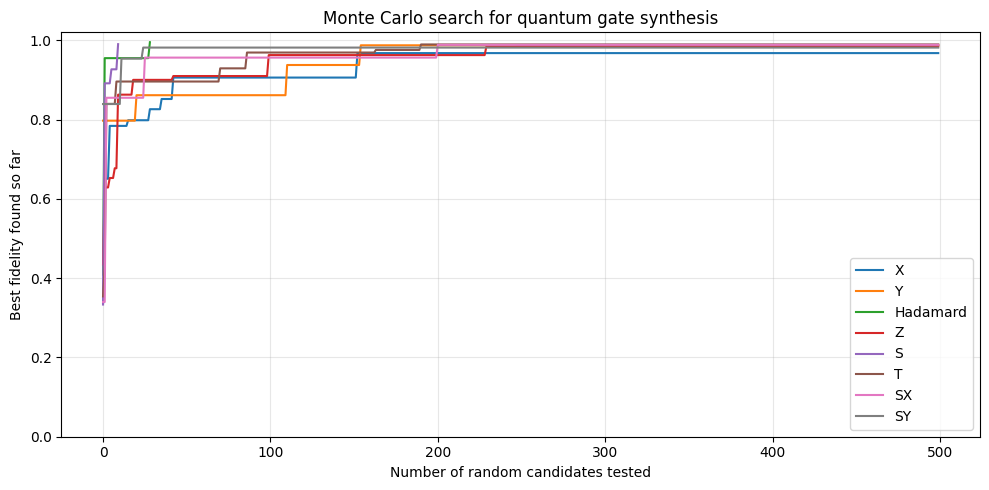

In [9]:
plt.figure(figsize=(10, 5))

for name, result in search_results.items():
    plt.plot(result["history"], label=name)

plt.xlabel("Number of random candidates tested")
plt.ylabel("Best fidelity found so far")
plt.title("Monte Carlo search for quantum gate synthesis")
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 7 Parameters that define the search problem

The results depend on several modelling and numerical choices:

- **Target gate:** the unitary operation we want to synthesize.
- **Number of pulse segments:** the number of independently optimized amplitudes and the temporal resolution of the waveform.
- **Pulse amplitude bounds:** restrict the allowed control strengths.
- **Total gate duration:** determines the available time for the system to reach the target.
- **Drift Hamiltonian and detuning:** determine the natural evolution during the pulse.
- **Control axes:** determine which Hamiltonian directions can be deliberately driven.